## OR-Library Benchmark Evaluation (MKNAP1)

This notebook evaluates knapsack algorithms on OR-Library MKNAP1 benchmark instances.
Known optimal solution values are provided for comparison.


In [2]:
%load_ext autoreload
%autoreload 2

import sys, os
sys.path.append(os.path.abspath(".."))
sys.path.append(os.path.abspath("../src"))

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="whitegrid")

from src.generator import generate_instance
from src.utils import (
    pretty_print_instance,
    weight_of_solution,
    timeit,
    value_of_solution,
)
print("Notebook ready.")


Notebook ready.


In [ ]:
from src.generator import generate_instance
from src.brute_force import brute_force
from src.greedy import greedy_by_value, greedy_by_weight, greedy_by_ratio
from src.dp import dp_bottom_up_reconstruct, dp_top_down_reconstruct
from src.fptas import fptas_knapsack
from src.branch_and_bound import branch_and_bound
from src.utils import timeit, weight_of_solution

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()


## Dataset

MKNAP1 benchmark problems are used.
Each problem contains item profits, weights, and multiple constraints.
For compatibility with implemented solvers, a single constraint is selected.


In [4]:
from pathlib import Path

def load_mknap1(path):
    """
    Load OR-Library mknap1 file.
    Handles float values correctly.
    """
    path = Path(path)
    with open(path, "r") as f:
        tokens = f.read().split()

    # Convert everything to float first
    data = list(map(float, tokens))

    idx = 0
    K = int(data[idx])   # number of test problems
    idx += 1

    problems = []

    for _ in range(K):
        n = int(data[idx])
        m = int(data[idx+1])
        opt = data[idx+2]   # optimal value (can be float)
        idx += 3

        profits = data[idx:idx+n]
        idx += n

        weights = []
        for _ in range(m):
            weights.append(data[idx:idx+n])
            idx += n

        capacities = data[idx:idx+m]
        idx += m

        problems.append({
            "n": n,
            "m": m,
            "opt": opt,
            "profits": profits,
            "weights": weights,
            "capacities": capacities
        })

    return problems


In [5]:
mknap_path = Path("benchmarks/orlib/mknap1.txt")
mknap_problems = load_mknap1(mknap_path)

print(f"Loaded {len(mknap_problems)} benchmark problems\n")

for i, p in enumerate(mknap_problems):
    print(f"Problem {i+1}: n={p['n']}, m={p['m']}, optimal={p['opt']}")


Loaded 7 benchmark problems

Problem 1: n=6, m=10, optimal=3800.0
Problem 2: n=10, m=10, optimal=8706.1
Problem 3: n=15, m=10, optimal=4015.0
Problem 4: n=20, m=10, optimal=6120.0
Problem 5: n=28, m=10, optimal=12400.0
Problem 6: n=39, m=5, optimal=10618.0
Problem 7: n=50, m=5, optimal=16537.0


In [6]:
def to_single_constraint_knapsack(problem, constraint_id=0):
    """
    Convert multi-constraint MKP problem into
    single-constraint knapsack instance.
    """
    items = []
    profits = problem["profits"]
    weights = problem["weights"][constraint_id]
    capacity = problem["capacities"][constraint_id]

    for i in range(problem["n"]):
        items.append((profits[i], weights[i], i))

    return items, capacity


## Experimental Setup

Each algorithm is executed on selected benchmark problems.
Runtime and solution value are recorded.
Algorithms not applicable to a given instance are skipped.


In [7]:
benchmark_results = {}

for idx, prob in enumerate(mknap_problems[:7]):
    raw_items, cap = to_single_constraint_knapsack(prob, constraint_id=0)
    n = len(raw_items)

    print(f"\n=== MKNAP1 Problem {idx+1} (n={n}) ===")
    print(f"Known Optimal Value: {prob['opt']}")
    print(f"Capacity: {cap}")

    # --------------------------------------------------
    # Handle zero-weight items safely (THEORETICALLY CORRECT)
    # --------------------------------------------------
    zero_weight_items = [(v, w, i) for (v, w, i) in raw_items if w == 0 and v > 0]
    normal_items = [(v, w, i) for (v, w, i) in raw_items if w > 0]

    guaranteed_value = sum(v for (v, _, _) in zero_weight_items)

    results = {}

    # --------------------------------------------------
    # Brute Force (n < 30 only)
    # --------------------------------------------------
    if len(normal_items) < 30:
        t_bf, (bf_val, bf_sol) = timeit(brute_force)(normal_items, cap)
        results["Brute Force"] = {
            "value": bf_val + guaranteed_value,
            "time": t_bf
        }
    else:
        results["Brute Force"] = {"value": None, "time": None}

    # --------------------------------------------------
    # Greedy Algorithms (safe now)
    # --------------------------------------------------
    for name, fn in [
        ("Greedy Value", greedy_by_value),
        ("Greedy Weight", greedy_by_weight),
        ("Greedy Ratio", greedy_by_ratio),
    ]:
        try:
            t, (v, sol) = timeit(fn)(normal_items, cap)
            results[name] = {
                "value": v + guaranteed_value,
                "time": t
            }
        except ZeroDivisionError:
            results[name] = {"value": None, "time": None}

    # --------------------------------------------------
    # Dynamic Programming (integers only)
    # --------------------------------------------------
    weights_are_int = all(float(w).is_integer() for (_, w, _) in normal_items)
    cap_is_int = float(cap).is_integer()

    if weights_are_int and cap_is_int:
        cap_int = int(cap)
        items_int = [(v, int(w), i) for (v, w, i) in normal_items]

        t_dpbu, (dpbu_val, dpbu_sol, _) = timeit(
            dp_bottom_up_reconstruct
        )(items_int, cap_int)

        t_dptd, (dptd_val, dptd_sol) = timeit(
            dp_top_down_reconstruct
        )(items_int, cap_int)

        results["DP Bottom-Up"] = {
            "value": dpbu_val + guaranteed_value,
            "time": t_dpbu
        }
        results["DP Top-Down"] = {
            "value": dptd_val + guaranteed_value,
            "time": t_dptd
        }
    else:
        results["DP Bottom-Up"] = {"value": None, "time": None}
        results["DP Top-Down"] = {"value": None, "time": None}

    # --------------------------------------------------
    # Branch & Bound (NOW SAFE)
    # --------------------------------------------------
    t_bnb, (bnb_val, bnb_sol, _) = timeit(branch_and_bound)(normal_items, cap)
    results["Branch & Bound"] = {
        "value": bnb_val + guaranteed_value,
        "time": t_bnb
    }

    benchmark_results[f"Problem {idx+1}"] = results

print("\n✔ All benchmark algorithms executed safely and correctly.")



=== MKNAP1 Problem 1 (n=6) ===
Known Optimal Value: 3800.0
Capacity: 80.0

=== MKNAP1 Problem 2 (n=10) ===
Known Optimal Value: 8706.1
Capacity: 450.0

=== MKNAP1 Problem 3 (n=15) ===
Known Optimal Value: 4015.0
Capacity: 550.0

=== MKNAP1 Problem 4 (n=20) ===
Known Optimal Value: 6120.0
Capacity: 550.0

=== MKNAP1 Problem 5 (n=28) ===
Known Optimal Value: 12400.0
Capacity: 930.0

=== MKNAP1 Problem 6 (n=39) ===
Known Optimal Value: 10618.0
Capacity: 600.0

=== MKNAP1 Problem 7 (n=50) ===
Known Optimal Value: 16537.0
Capacity: 800.0

✔ All benchmark algorithms executed safely and correctly.


In [8]:
rows = []

for prob_name, res in benchmark_results.items():
    for algo, r in res.items():
        rows.append({
            "Problem": prob_name,
            "Algorithm": algo,
            "Value": r["value"],
            "Time": r["time"]
        })

df_all = pd.DataFrame(rows)
# display(df_all)


In [9]:
problem_tables = {}

for prob in df_all["Problem"].unique():
    table = df_all[df_all["Problem"] == prob].copy()
    problem_tables[prob] = table
    print(f"\n=== Results for {prob} ===")
    display(table)



=== Results for Problem 1 ===


,Problem,Algorithm,Value,Time
0,Problem 1,Brute Force,3900.0,0.000054
1,Problem 1,Greedy Value,3600.0,0.000006
2,Problem 1,Greedy Weight,2400.0,0.000004
3,Problem 1,Greedy Ratio,3900.0,0.000003
4,Problem 1,DP Bottom-Up,3900.0,0.000101
5,Problem 1,DP Top-Down,3900.0,0.000094
6,Problem 1,Branch & Bound,3900.0,0.000044



=== Results for Problem 2 ===


,Problem,Algorithm,Value,Time
7,Problem 2,Brute Force,10059.9,0.002706
8,Problem 2,Greedy Value,9850.0,0.000014
9,Problem 2,Greedy Weight,4539.4,0.000007
10,Problem 2,Greedy Ratio,10059.9,0.000007
11,Problem 2,DP Bottom-Up,10059.9,0.001702
12,Problem 2,DP Top-Down,10059.9,0.000440
13,Problem 2,Branch & Bound,10059.9,0.000087



=== Results for Problem 3 ===


...

,Problem,Algorithm,Value,Time
28,Problem 5,Brute Force,13300.0,697.763322
29,Problem 5,Greedy Value,12400.0,0.000014
30,Problem 5,Greedy Weight,9445.0,0.000008
31,Problem 5,Greedy Ratio,13070.0,0.000008
32,Problem 5,DP Bottom-Up,13300.0,0.006112
33,Problem 5,DP Top-Down,13300.0,0.010050
34,Problem 5,Branch & Bound,13300.0,0.000146



=== Results for Problem 6 ===


,Problem,Algorithm,Value,Time
35,Problem 6,Brute Force,NaN,NaN
36,Problem 6,Greedy Value,8704.0,0.000010
37,Problem 6,Greedy Weight,8363.0,0.000013
38,Problem 6,Greedy Ratio,10937.0,0.000010
39,Problem 6,DP Bottom-Up,11040.0,0.005018
40,Problem 6,DP Top-Down,11040.0,0.010300
41,Problem 6,Branch & Bound,11040.0,0.015798



=== Results for Problem 7 ===


,Problem,Algorithm,Value,Time
42,Problem 7,Brute Force,NaN,NaN
43,Problem 7,Greedy Value,13863.0,0.000015
44,Problem 7,Greedy Weight,13077.0,0.000012
45,Problem 7,Greedy Ratio,17021.0,0.000032
46,Problem 7,DP Bottom-Up,17038.0,0.009394
47,Problem 7,DP Top-Down,17038.0,0.018971
48,Problem 7,Branch & Bound,17038.0,0.002799


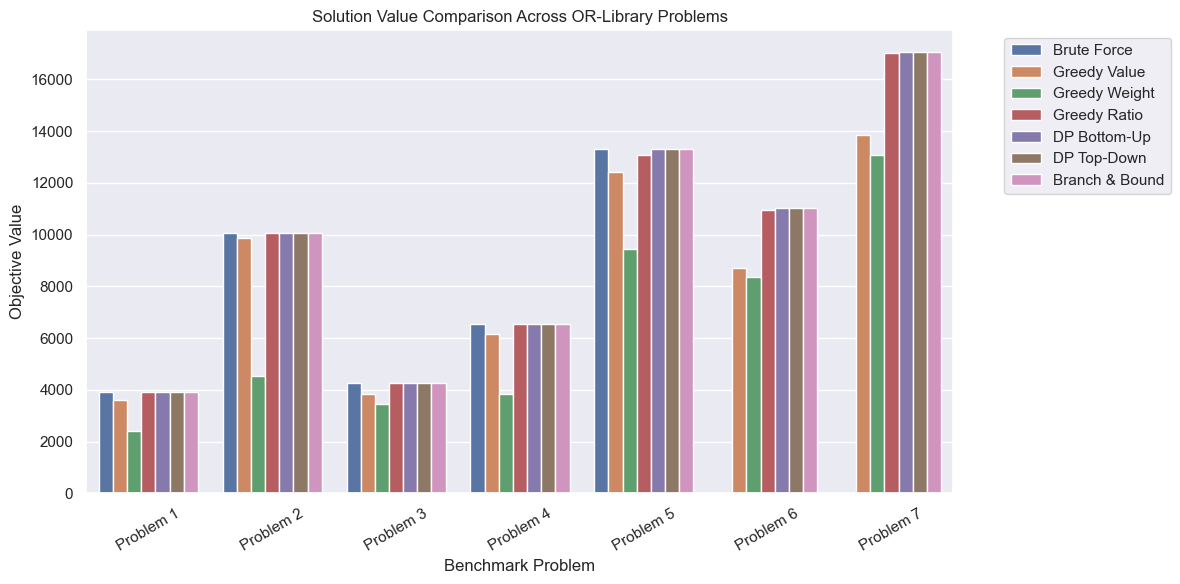

In [10]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=df_all,
    x="Problem",
    y="Value",
    hue="Algorithm"
)

plt.title("Solution Value Comparison Across OR-Library Problems")
plt.ylabel("Objective Value")
plt.xlabel("Benchmark Problem")
plt.xticks(rotation=30)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [11]:
opt_map = {
    f"Problem {i+1}": p["opt"]
    for i, p in enumerate(mknap_problems)
}

gap_rows = []

for prob, opt in opt_map.items():
    for algo, r in benchmark_results[prob].items():
        if r["value"] is not None:
            gap = (opt - r["value"]) / opt
            gap_rows.append({
                "Problem": prob,
                "Algorithm": algo,
                "Relative Gap": gap
            })

df_gap = pd.DataFrame(gap_rows)
# display(df_gap)


## Relative Optimality Gap

Relative gap is computed as:

(Optimal − Algorithm Value) / Optimal

Lower values indicate better solution quality.


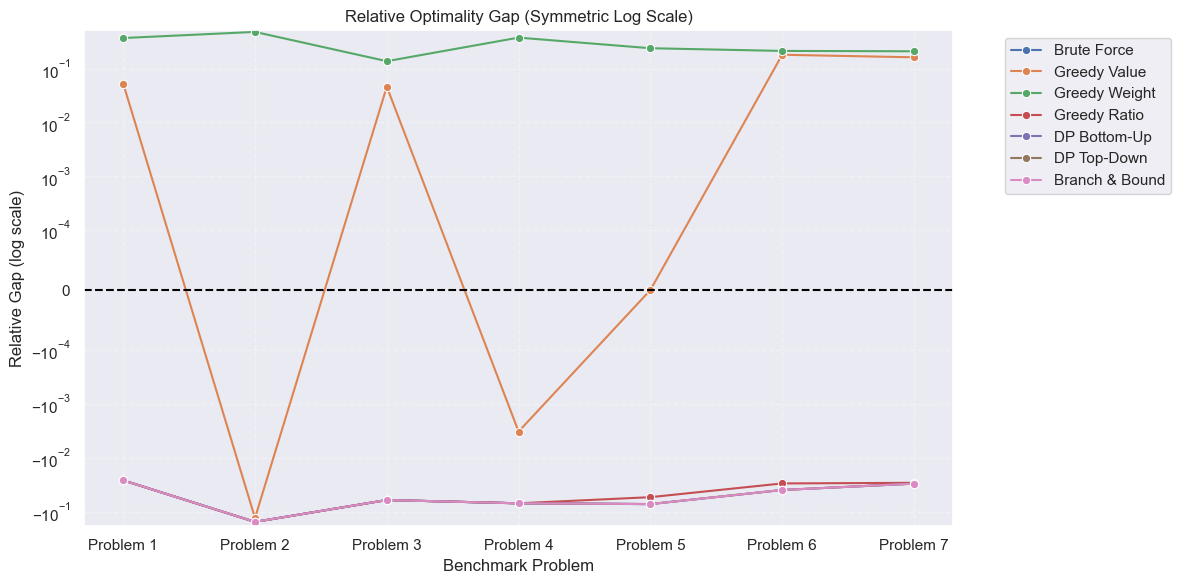

In [12]:
plt.figure(figsize=(12,6))

sns.lineplot(
    data=df_gap,
    x="Problem",
    y="Relative Gap",
    hue="Algorithm",
    marker="o"
)

plt.axhline(0, linestyle="--", color="black")
plt.yscale("symlog", linthresh=1e-4)
plt.title("Relative Optimality Gap (Symmetric Log Scale)")
plt.ylabel("Relative Gap (log scale)")
plt.xlabel("Benchmark Problem")
plt.grid(True, which="both", linestyle="--", alpha=0.3)

plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


## Notes

Published optimal values correspond to the original multi-constraint problem.
Single-constraint reductions may lead to different solution values.


## Runtime Comparison

Algorithm runtimes are compared across benchmark problems
to evaluate practical efficiency.


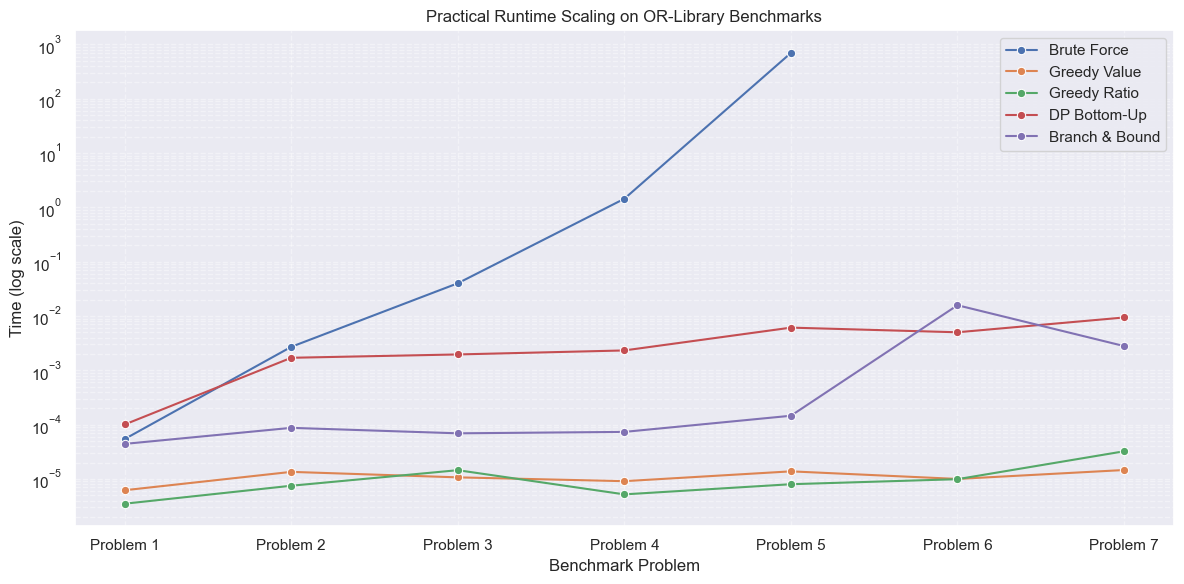

In [13]:
plt.figure(figsize=(12,6))

# Practical times
sns.lineplot(
    data=df_all[df_all["Algorithm"].isin([
        "Greedy Ratio", "DP Bottom-Up", "Branch & Bound","Brute Force","Greedy Wight","Greedy Value"
    ])],
    x="Problem",
    y="Time",
    hue="Algorithm",
    marker="o"
)

plt.yscale("log")

plt.title("Practical Runtime Scaling on OR-Library Benchmarks")
plt.ylabel("Time (log scale)")
plt.xlabel("Benchmark Problem")
plt.grid(True, which="both", linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()
